In [140]:
##### Josie Pettis #####
#  OBAN Assignment 3
#  Due: October 23,2026

"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [141]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles
import pandas as pd

In [142]:
### Create function for Cressman Analysis ###
def cressman_weight(d, R):
    #Cressman Weight function. d is the distances between an analysis point and each observation R is ROI. Returns 0 if 
    #d greater than R, and (R^2 - d^2)/(R^2 + d^2) if d less than or equal to R
    w=np.where(d<=R,(R**2-d**2)/(R**2+d**2),0.0)
    return w

def cressman_analysis(x, y, xd, yd, vals, R): #Cressman weighted average at one analysis point.
    #returns nan if no points are within roi
    d=np.sqrt((xd-x)**2+(yd-y)**2) #distance from the analysis point to every data point
    w=cressman_weight(d, R) #Using the function above.. Cressman weight for each data point putting 0 for any point farther than R
    wsum=w.sum() #total weight
    if wsum==0:
        return np.nan
    return (w*vals).sum()/wsum #weighted average: sum(w * value) / sum(w)

In [143]:
### Create function for bilinear interpolation ###
#From notes in class, we used the floor and ceiling function to determine all the points near the observations, which ultimately
#helps us identify the point closer to observations, if not, we need to utilize cressman to smooth it out
def bilinear_interp(field, i_frac, j_frac, nx, ny):
    if np.isnan(i_frac) or np.isnan(j_frac):
        return np.nan
    i0=int(np.floor(i_frac)) #grid index below the point in x
    i1=int(np.ceil(i_frac)) #grid index above the point in x
    j0=int(np.floor(j_frac)) #grid index below the point in y
    j1=int(np.ceil(j_frac)) #grid index above the point in y
    #need all four surrounding corners to exist inside the grid (as said in instructions, utilize nan if they dont)
    if i0<0 or j0<0 or i1>nx-1 or j1>ny-1: #setting our nan's
        return np.nan
    di=i_frac-i0 #distance into the cell in x (0 at i0, 1 at i1)
    dj=j_frac-j0 #distance into the cell in y (0 at j0, 1 at j1)
    val=(field[i0, j0]*(1-di)*(1-dj)+field[i1, j0]*di*(1-dj)+field[i0, j1]*(1-di)*dj+field[i1, j1]*di*dj)
    return val

In [144]:
### Read in observations ###
name=['Station ID','Latitude','Longitude','500mb Height (m)','500mb Wind Direction','500mb Wind Speed (kt)'] #create column names
df=pd.read_csv('RAOBs_201903131200.txt',sep=',',header=None,names=name) #i am utilizing Pandas to read in the text file,so I added it to the Modules.

#Knowns
phi_0=np.radians(60)
lambda_0=-100
m=1/15000000
rho=6371*1e3 #calculate via SI units

In [145]:
### Set up analysis map with a 21x27 rectangular grid of points ###

#from assignment 2
mX,mY=21,27 # x (N to S) and y (W to E)
dx=dy=1.27 #cm
xo,yo=25,-15.5 #cm

#x increases to the south y increases eastward.
x_fix=xo+dx*np.arange(mX)
y_fix=yo+dy*np.arange(mY)
x_cm,y_cm=np.meshgrid(x_fix,y_fix,indexing='ij')   #shape 21x27

x=x_cm/100.0/m   #map cm onto image plane
y=y_cm /100.0/m
psi0=np.pi/2-phi_0  #co-latitude
r=np.sqrt(x**2+y**2) #calculate using distance eqn
phi=np.pi/2-2.0*np.arctan(r/(rho*(1.0+np.cos(psi0)))) #from the notes
lam=np.arctan2(y,x) #lambda=lon-lam0 (east positive)
lat=np.degrees(phi)
lon=(lambda_0+np.degrees(lam)+180.0)%360.0-180.0

In [146]:
### convert obs lat/long to x,y ###
phi=np.radians(df['Latitude'].values)
lam=np.radians(df['Longitude'].values-lambda_0) #east positive
sigma=(1.0+np.sin(phi_0))/(1.0+np.sin(phi)) #calculating sigma/scale factor
R=m*sigma*rho*np.cos(phi) #creates radius of lat circle found in notes
df['x_cm']=100.0*R*np.cos(lam) #x should theoretically increases southward IN CENTIMETERS
df['y_cm']=100.0*R*np.sin(lam) #y should theoretically increases eastward IN CENTIMETERS

In [147]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin

obs_x=df['x_cm'].values #observation locations in centimeters
obs_y=df['y_cm'].values
obs_z=df['500mb Height (m)'].values
n_obs=135 #number of obs stations 135

df['i']=(df['x_cm']-xo)/dx #fractional grid indices for each observation (do algebra to the equation for ind(x) from class)
df['j']=(df['y_cm']-yo)/dy #fractional grid indices for each observation (do algebra to the equations for ind(y) from class)

X, Y=x_cm, y_cm #analysis grid (cm), from earlier setup
nx, ny=X.shape #21x27

#dmin: average distance between nearest-neighbor stations
nearest_dist=np.zeros(n_obs)
for k in range(n_obs):
    d=np.sqrt((obs_x-obs_x[k])**2+(obs_y-obs_y[k])**2) #distance from station k to every station
    d[k]=np.inf #ignore station k distance to itself
    nearest_dist[k]=d.min() #factoring in other closer station
dmin=nearest_dist.mean()

#ALL OF THESE ARE IN CM!!!!!!
R1=4.0*dmin
R2=2.5*dmin
R3=1.5*dmin
print(dmin, R1, R2, R3)

2.5548700820071426 10.21948032802857 6.387175205017856 3.832305123010714


In [148]:
### First analysis, no successive corrections ###
#directly from the observations, using R1 since this is the first pass
A1=np.full((nx, ny), np.nan) #21x27 array with every value set to NaN
for i in range(nx): #grid rows y west to east
    for j in range(ny):
        A1[i, j]=cressman_analysis(X[i, j], Y[i, j], obs_x, obs_y, obs_z, R1) #replace nan with Cressman analysis value at grid point. nan if not in ROI

In [149]:
### Next Analyses ###
#Pass 1 analysis at each observation location
A1_at_obs=np.full(n_obs, np.nan)
for k in range(n_obs): #Start with bilinear interperatation
    v=bilinear_interp(A1, df['i'].values[k], df['j'].values[k], nx, ny)
    if np.isnan(v): #IF THE PTS AREN'T WITHIN THE GRID
        v=cressman_analysis(obs_x[k], obs_y[k], X.ravel(), Y.ravel(), A1.ravel(), R1)
    A1_at_obs[k]=v
    
#Pass 2 look at every station within R2, compare that station's real observed height to what was predicted, and push the value toward 
#the obs by a Cressman-weighted average of using differences.
A2=np.full((nx, ny), np.nan) #similar process as 1 start as nans
valid=np.isfinite(A1_at_obs) #only use stations that got through estimate in pass 1
for i in range(nx):
    for j in range(ny):
        if np.isnan(A1[i, j]):
            continue
        d=np.sqrt((obs_x[valid] - X[i, j])**2 + (obs_y[valid] - Y[i, j])**2) #dist to each station
        w=cressman_weight(d, R2) #Cressman weight for each station, using radius R2
        wsum=w.sum() #total weight where 0 means no station is within R2
        if wsum==0:
            A2[i, j]=A1[i, j] #if there is no nearby obs, the correction is NOT applied
            continue
        # weighted average of observed-predicted across nearby stations=correction
        correction=(w*(obs_z[valid]-A1_at_obs[valid])).sum()/wsum
        A2[i, j]=A1[i, j]+correction #apply the correction

#Use second pass at each observation location starting with bilinear, Cressman as a backup
A2_at_obs=np.full(n_obs, np.nan)
for k in range(n_obs):
    v=bilinear_interp(A2, df['i'].values[k], df['j'].values[k], nx, ny)
    if np.isnan(v):
        v=cressman_analysis(obs_x[k], obs_y[k], X.ravel(), Y.ravel(), A2.ravel(), R2)
    A2_at_obs[k]=v

#Pass 3 Same correction procedure as pass 2, but starting from A2 and using the smaller/final radius of influence R3.
A3=np.full((nx, ny), np.nan) #similar process as 1 start as nans
valid=np.isfinite(A2_at_obs) #only use stations that got a valid second pass
for i in range(nx):
    for j in range(ny):
        if np.isnan(A2[i, j]):
            continue
        d=np.sqrt((obs_x[valid]-X[i, j])**2+(obs_y[valid]-Y[i, j])**2) #dist to each station
        w=cressman_weight(d, R3) #Cressman weight for each station, using radius R3
        wsum=w.sum() #total weight where 0 means no station is within R3
        if wsum==0:
            A3[i, j]=A2[i, j] #if there is no nearby obs, the correction is NOT applied
            continue
        #weighted average of observed-estimate(from pass 2) across nearby stations=correction
        correction=(w*(obs_z[valid]-A2_at_obs[valid])).sum()/wsum
        A3[i, j]=A2[i, j]+correction #apply correction to the pass 2 values

#Use third pass at each observation location starting with bilinear, Cressman as a backup
A3_at_obs=np.full(n_obs, np.nan)
for k in range(n_obs):
    v=bilinear_interp(A3, df['i'].values[k], df['j'].values[k], nx, ny)
    if np.isnan(v):
        v=cressman_analysis(obs_x[k], obs_y[k], X.ravel(), Y.ravel(), A3.ravel(), R3)
    A3_at_obs[k]=v

In [150]:
### Calculate Analysis Differences

# ~Question 2~: Differences between analysis fields (PLOT THESE LATER)
diff_21=A2-A1 
diff_31=A3-A1 
diff_32=A3-A2

#~Question 3~ (Root Mean Square=rms)
K1=np.sum(np.isfinite(A1_at_obs)) #Total number of obs in R1
K2=np.sum(np.isfinite(A2_at_obs)) #Total number of obs in R2
K3=np.sum(np.isfinite(A3_at_obs)) #Total number of obs in R3

#Using the formula in the assignmnet
rms_1=np.sqrt(np.nansum((obs_z-A1_at_obs)**2)/K1)
rms_2=np.sqrt(np.nansum((obs_z-A2_at_obs)**2)/K2)
rms_3=np.sqrt(np.nansum((obs_z-A3_at_obs)**2)/K3)

print(rms_1, K1)
print(rms_2, K2)
print(rms_3, K3)

85.3508434938349 114
37.95754682302226 108
11.56933318675876 101


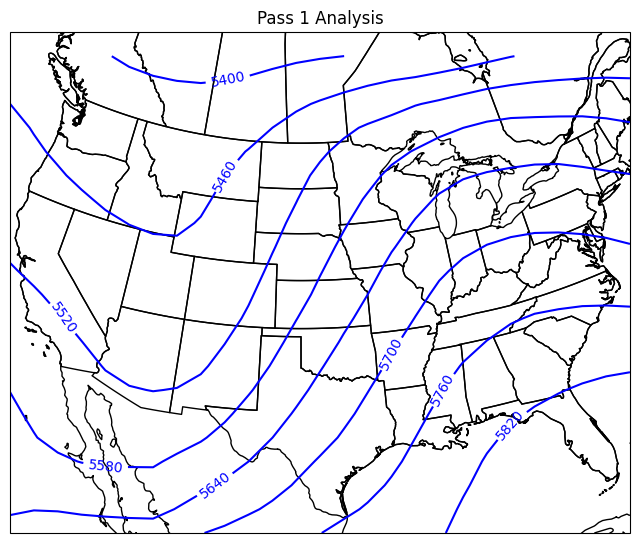

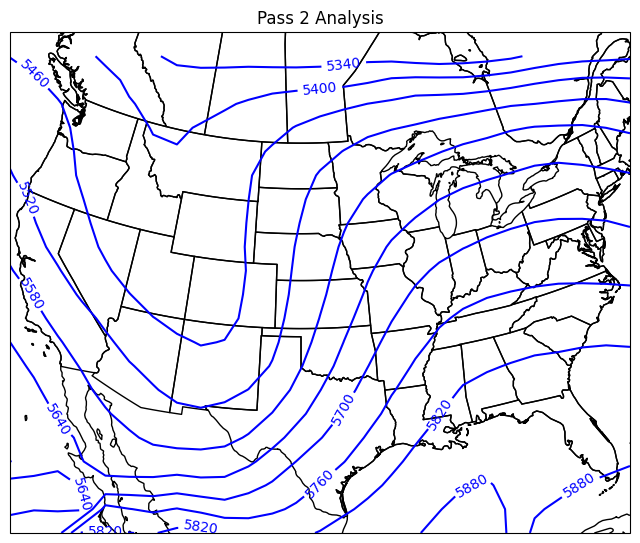

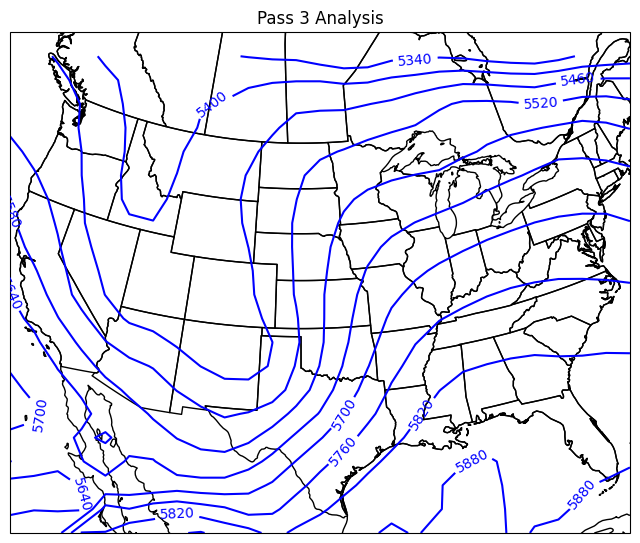

In [151]:
### Plot 500mb analyses over a map ###
#use old code...
#From the last assignment
globe=ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj=ccrs.Stereographic(central_longitude=lambda_0, central_latitude=90, true_scale_latitude=phi_0, globe=globe)

#Pass 1 (R1, no successive corrections)
fig=plt.figure(figsize=(8,8))
ax1=fig.add_subplot(111, projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
cs1=ax1.contour(lon, lat, A1, colors='b', levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, levels=np.arange(0,8000,60))
ax1.set_title('Pass 1 Analysis')
plt.savefig('analysis_pass1.png')
plt.show()

#Pass 2 (R2)
fig=plt.figure(figsize=(8,8))
ax2=fig.add_subplot(111, projection=proj)
ax2.add_feature(cfeature.STATES)
ax2.add_feature(cfeature.COASTLINE)
cs2=ax2.contour(lon, lat, A2, colors='b', levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs2, levels=np.arange(0,8000,60))
ax2.set_title('Pass 2 Analysis')
plt.savefig('analysis_pass2.png')
plt.show()

# Pass 3 (R3 = 1.5*dmin)
fig=plt.figure(figsize=(8,8))
ax3=fig.add_subplot(111, projection=proj)
ax3.add_feature(cfeature.STATES)
ax3.add_feature(cfeature.COASTLINE)
cs3=ax3.contour(lon, lat, A3, colors='b', levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs3, levels=np.arange(0,8000,60))
ax3.set_title('Pass 3 Analysis')
plt.savefig('analysis_pass3.png')
plt.show()

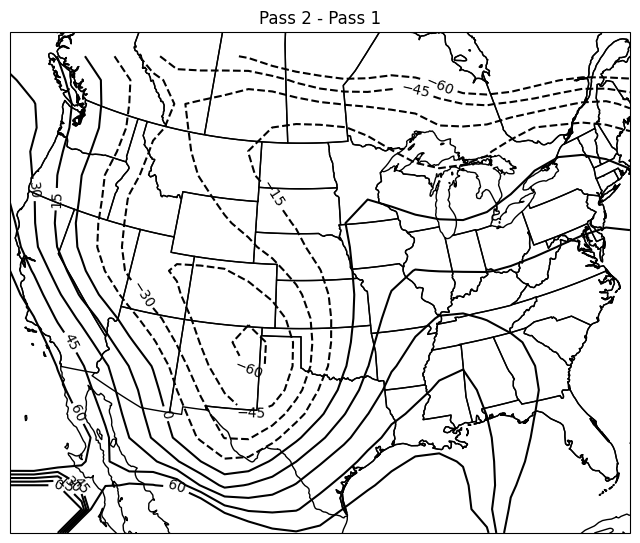

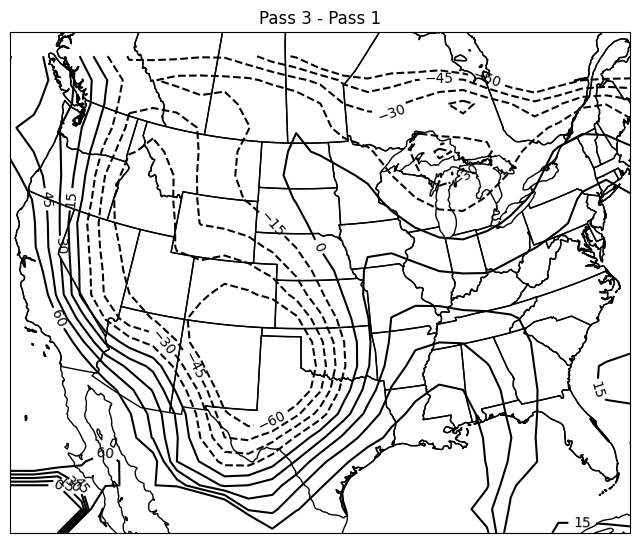

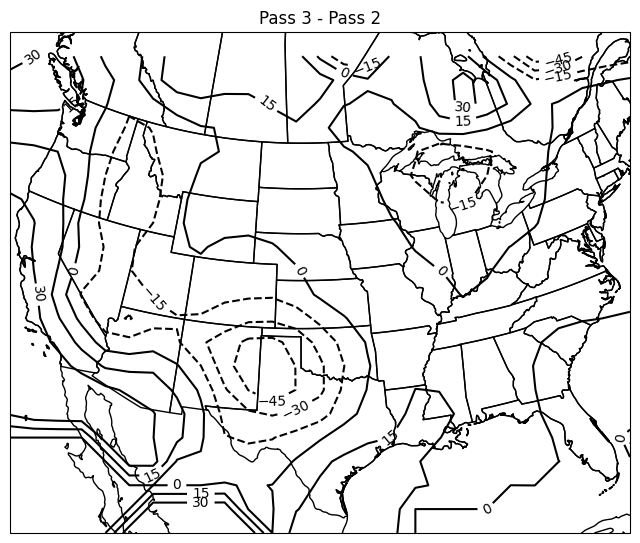

In [152]:
### Plot Analysis Differences ###
globe=ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj=ccrs.Stereographic(central_longitude=lambda_0, central_latitude=90, true_scale_latitude=phi_0, globe=globe)

# diff levels centered on zero, since these are differences (can be positive or negative)
diff_levels=np.arange(-60, 65, 15)

#A2-A1
fig=plt.figure(figsize=(8,8))
ax1=fig.add_subplot(111, projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
cs1=ax1.contour(lon, lat, diff_21, colors='k', levels=diff_levels, transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, levels=diff_levels)
ax1.set_title('Pass 2 - Pass 1')
plt.savefig('pass2__pass1.png')
plt.show()

#A3-A1
fig=plt.figure(figsize=(8,8))
ax2=fig.add_subplot(111, projection=proj)
ax2.add_feature(cfeature.STATES)
ax2.add_feature(cfeature.COASTLINE)
cs2=ax2.contour(lon, lat, diff_31, colors='k', levels=diff_levels, transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs2, levels=diff_levels)
ax2.set_title('Pass 3 - Pass 1')
plt.savefig('pass3__pass1.png')
plt.show()

#A3-A2
fig=plt.figure(figsize=(8,8))
ax3=fig.add_subplot(111, projection=proj)
ax3.add_feature(cfeature.STATES)
ax3.add_feature(cfeature.COASTLINE)
cs3=ax3.contour(lon, lat, diff_32, colors='k', levels=diff_levels, transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs3, levels=diff_levels)
ax3.set_title('Pass 3 - Pass 2')
plt.savefig('pass3__pass2.png')
plt.show()

In [153]:
### Store the analyses in text files: Pulled from assignment 2###
analyses = [A1, A2, A3]
ROI = [R1, R2, R3]
for p, field in enumerate(analyses):
    out=np.column_stack([np.repeat(np.arange(nx),ny),np.tile(np.arange(ny),nx),x_cm.ravel(),y_cm.ravel(),lat.ravel(),lon.ravel(),field.ravel()])
    fname=f'analysis_pass.txt'
    np.savetxt(fname,out,header='i j x_cm y_cm lat lon height_m',fmt=['%d','%d','%.4f','%.4f','%.4f','%.4f','%.4f'])

In [154]:
### Store the difference fields in text files ###
diffs = [diff_21, diff_31, diff_32]
names = ['diff_pass2_minus_pass1', 'diff_pass3_minus_pass1', 'diff_pass3_minus_pass2']
for p, field in enumerate(diffs):
    out=np.column_stack([np.repeat(np.arange(nx),ny),np.tile(np.arange(ny),nx),x_cm.ravel(),y_cm.ravel(),lat.ravel(),lon.ravel(),field.ravel()])
    fname=f'{names[p]}.txt'
    np.savetxt(fname,out,header='i j x_cm y_cm lat lon height_diff_m',fmt=['%d','%d','%.4f','%.4f','%.4f','%.4f','%.4f'])

In [155]:
### Store RMS values in text file ###
passes = np.array([1, 2, 3])
ROI = np.array([R1, R2, R3])
K = np.array([K1, K2, K3])
rms = np.array([rms_1, rms_2, rms_3])
out=np.column_stack([passes,ROI,K,rms])
fname='rms.txt'
np.savetxt(fname,out,header='pass R_cm K rms_m',fmt=['%d','%.4f','%d','%.4f'])

In [156]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.

    Starting with the primary 3 Analysis charts...
    -Pass 1 Analysis: Overall the contours seem highly smooth. There are some noticable kinks in the plot specifically by the west coast
        of Mexico. There appears to be a deep trough just south of the Rockies, creating intense subgeostrophic flow south of the 4 
        corners. This trough begins to form into a ridge near the Great Lakes region.
    -Pass 2 Analysis: The contours appear to have the trough starting much closer to the 4 corners and the ridge in roughly the same area,
        however, there seems to be more isoheights present. We see that the contours drop to 530dm in Canada. Looking near the Southwest 
        boarder of the analysis chart, there appears to be a large kink in the isoheights rather than a smooth pattern. In this corner 
        specifically, there appears to be a strong thickness gradient near the corner (since the isoheights are tightly packed).
    -Pass 3 Analysis: The trough appears to have deepen heaviy into Texas, creating a strong thickness gradient, further supporting
        intense subgeostrophic patterns. The ridge looks to be more interesting with some areas appearing more zonal now. Shortwaves 
        (based off the heights) look to be more prominant near northern Wisconsin into Canada. Back at the southwest boarder, it looks
        like the isoheights have a closed value in the Gulf of California. We continue to see a bunch of kinks in the isoheights in this
        region, creating more of a discontinous feature in the map. Near Florida, there appears to be two 588dm lines. I can't see south
        of this region, but if I had to make an assumption, I believe there is a data point that is causing the separation of these 
        contours.
    Difference between analysis charts... Overall, there's a ton of variablity.
    -Pass 2 minus Pass 1: On my graphs, the dash line represents negative numbers (different intervals present), where the negative means
        that pass 2 displaced the heights to be less than the heights in pass 1. This happened heavily in the trough region we saw earlier.
        We also see negative values in Canada, where we saw the 534dm in pass 2. Vice versa with the solid lines, we see that in pass 2
        heights were displaced to be higher, specifically near areas in the southeast. Over the eastern United States some contours are 
        sparse there, so pass 1 already matched the observations well and pass 2 barely changed anything.
    -Pass 3 minus Pass 1: Similar idea with the dashed and solid lines here... We see an overall decrease in pass 3 over the trough region,
        but it appears to be more broad than the previous discussion. We see these lower heights extend into Texas, but quickly beyond the
        center of the trough, positive heights begin to appear starting in Mexico and arrising from the Gulf near Florida. I would also
        like to note near the southwest boarder we see tight contour lines, showing the uncertainty in the region.
    -Pass 3 minus Pass 2: Over the midwest some contours are sparse there, so pass 3 already matched the observations well and pass 2 
        barely changed anything. We see the most change near the base of the trough in Texas where pass 3 identified lower heights.
        Looking in the southwestern side of the chart, we see a lot of variability with the height differences where most are observing 
        pass 3 to have higher heights than pass 2. On the northern part of the chart we can see that most heights are read to be lower
        in pass 3 than pass 2.
        
2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    
    The three analyses show the same idea with a trough over the western United States, a ridge over the southeast into the northeast, and
    heights increasing toward the south. They change in the amount of detail. Pass 1 is the smoothest with broad curving contours. Pass 2 
    has tighter curvature in the trough and ridge. Pass 3 has more detailed kinks, with the contours following station values most closely.
    The corrections are largest over the Rockies and southern plains and along the west coast. They are near zero over the eastern region.
    Pass 1 already matched the observations well in the east, since the height field is smooth, and it's poor where the field has more 
    structure. The contours south of California's coast is due to the lack of data in the ocean and it isn’t a real feature. I would say
    pass 1 is the smoothest, and the cause is the ROI. A large radius averages each grid point over many stations eliminating errors with 
    smaller features. It flattens sharp troughs and ridges, which is why pass 1 was too high or too low when comparing other
    passes. Each later pass uses a smaller ROI; fewer stations contribute to each grid point. This shows up as a falling root mean square 
    differences from pass 1 to pass 3.

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?

    Increasing the successive correction passes allows the analysis to better fit the observations, hence why the root mean square
    differences decrease as you continue to push through more passes. Each pass in our case used a smaller ROI, but the weighted difference
    between the observations and the previous analysis can pick up the smaller scale features we may not observe with the first pass.
    I feel like depending on the case, this could be desirable, but I truly feel it may vary. One thing I noticed when we were doing these
    passes, we experienced a ton of noise, which could potentially stem from observation errors (if there are any). Additionally, there
    is a situation here where we could potentially overfit the contours; we can see this with smaller ROIs (like in the southwest corner
    in pass 3). If we decrease our ROI, we can see that we have less observations to base our passes on, which can cause massive 
    discrepancies. I believe in this specific case we should only go up to 3 passes. I believe 4 would make our values insane and almost
    unreliable. Having a chart that resolves the real structure of the synoptic scale while keeping the analysis smooth enough to ignore
    this noise is important, thus the radius and the number of passes has an overall influence when deciding station spacing resolution.

'''

"\n1 - Describe the general features that you see in your contoured analyses.\n\n    Starting with the primary 3 Analysis charts...\n    -Pass 1 Analysis: Overall the contours seem highly smooth. There are some noticable kinks in the plot specifically by the west coast\n        of Mexico. There appears to be a deep trough just south of the Rockies, creating intense subgeostrophic flow south of the 4 \n        corners. This trough begins to form into a ridge near the Great Lakes region.\n    -Pass 2 Analysis: The contours appear to have the trough starting much closer to the 4 corners and the ridge in roughly the same area,\n        however, there seems to be more isoheights present. We see that the contours drop to 530dm in Canada. Looking near the Southwest \n        boarder of the analysis chart, there appears to be a large kink in the isoheights rather than a smooth pattern. In this corner \n        specifically, there appears to be a strong thickness gradient near the corner (since